## 1. Постановка задачи


В данном проекте вы решите настоящую бизнес-задачу в области маркетинга. Вам предстоит произвести сегментацию клиентов на основе их покупательской способности, частоты совершения заказов и срока давности последнего заказа, а также определить оптимальную стратегию взаимодействия с ними.
<center> <img src=https://salesupnow.ru/storage/app/media/pipeople.png align="right" width="300"/> </center>

Маркетинг — неотъемлемая часть любого бизнеса. Для повышения прибыли компании важно понимать своего клиента, его пожелания и предпочтения. С появлением электронной коммерции, или онлайн-продаж, стало намного проще собирать данные о клиентах, анализировать их, находить закономерности и реализовывать маркетинговые кампании.

Большинство интернет-магазинов используют инструменты веб-аналитики, чтобы отслеживать просмотры страниц, количество и поведение посетителей и коэффициент отказов. Но отчёта из Google Analytics или аналогичной системы может быть недостаточно для полного понимания того, как клиенты взаимодействуют с сайтом. Компаниям важно иметь возможность быстро и точно реагировать на перемены в поведении клиентов, создавая инструменты, которые обнаруживают эти изменения практически в режиме реального времени.

Машинное обучение помогает поисковой системе анализировать огромное количество данных о посетителях платформы, узнавать модели поведения профессиональных покупателей, определять категорию клиентов (например, лояльные/перспективные/новички/спящие/ушедшие) и выбирать правильную стратегию взаимодействия с ними.

Стоит также отметить, что компании, использующие машинное обучение на своих платформах электронной коммерции, могут постоянно повышать эффективность бизнес-процессов: настраивать товарную выборку персонально для каждого покупателя и предлагать выгодную цену в соответствии с бюджетом клиента и т. д. Эта задача относится к категории построения рекомендательных систем, речь о которых пойдёт в следующем разделе нашего курса.

Как правило, наборы данных для электронной коммерции являются частной собственностью и, следовательно, их трудно найти среди общедоступных данных. 

**Бизнес-задача:** произвести сегментацию существующих клиентов, проинтерпретировать эти сегменты и определить стратегию взаимодействия с ними.

**Техническая задача для вас как для специалиста в Data Science:** построить модель кластеризации клиентов на основе их покупательской способности, частоты заказов и срока давности последней покупки, определить профиль каждого из кластеров.

**Основные цели проекта:**
1. Произвести предобработку набора данных.
2. Провести разведывательный анализ данных и выявить основные закономерности.
3. Сформировать категории товаров и клиентов. 
4. Построить несколько моделей машинного обучения, решающих задачу кластеризации клиентов, определить количество кластеров и проинтерпретировать их.
5. Спроектировать процесс предсказания категории интересов клиента и протестировать вашу модель на новых клиентах.



## 2. Знакомство с данными. 

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

import plotly.graph_objs as go
import plotly.express as px
from plotly.subplots import make_subplots

from sklearn import mixture
from sklearn import manifold
from sklearn import pipeline
from sklearn import preprocessing
from sklearn import cluster
from sklearn import metrics
from sklearn import model_selection
from sklearn import decomposition
from sklearn import ensemble
import warnings 

from IPython.display import display, HTML

warnings.filterwarnings("ignore")

plt.rcParams["patch.force_edgecolor"] = True

Первым делом необходимо понять, с какими данными нам предстоит работать, и произвести базовую предобработку данных, переведя признаки в необходимые для дальнейшей работы форматы.


Для начала давайте познакомимся с нашими данными:

In [9]:
data = pd.read_csv(
    "./data/customer_segmentation_project.csv", 
    encoding="ISO-8859-1", 
    dtype={'CustomerID': str,'InvoiceID': str}
)
print('Data shape: {}'.format(data.shape))
data.head(5)

Data shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


Итак, у нас есть данные о более чем полумиллионе транзакций. Каждая из них описывается следующими признаками:

* InvoiceNo — номер счёта-фактуры (уникальный номинальный шестизначный номер, присваиваемый каждой транзакции; буква "C" в начале кода указывает на отмену транзакции);
* Stock Code — код товара (уникальное пятизначное целое число, присваиваемое каждому отдельному товару);
* Description — название товара;
* Quantity — количество каждого товара за транзакцию; 
* InvoiceDate — дата и время выставления счёта/проведения транзакции;
* UnitPrice — цена за единицу товара в фунтах стерлингов;
* CustomerID — идентификатор клиента (уникальный пятизначный номер, однозначно присваиваемый каждому клиенту);
* Country — название страны, в которой проживает клиент.

Проведём анализ структуры таблицы.


### Задание 2.1
Сколько столбцов в данных кодируются числовыми типами (int/float)?

In [10]:
print(f"Количество числовых столбцов: {data.select_dtypes(include='number').shape[1]}")

Количество числовых столбцов: 2


### Задание 2.2
Выберите столбцы, в которых есть хотя бы один пропуск:
* InvoiceNo
* StockCode
* Description
* CustomerID
* Country 

In [11]:
# Выводим только те колонки, где есть хотя бы один пропуск
missing_values = data.isna().sum()
missing_values = missing_values[missing_values > 0]

print("Столбцы с пропусками и их количество:")
print(missing_values)

Столбцы с пропусками и их количество:
Description      1454
CustomerID     135080
dtype: int64


### Задание 2.3
Судя по описанию задачи, нам должны были предоставить данные за годовой период — проверим, так ли это.

Преобразуйте столбец InvoiceDate в формат datetime.
Укажите, за какой промежуток времени представлены данные:

* 2010-12-01 to 2011-12-09
* 2011-12-01 to 2012-12-09
* 2010-01-01 to 2011-01-09
* 2020-12-01 to 2021-12-09


In [12]:
import pandas as pd

# 1. Преобразуем в datetime
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

# 2. Находим минимальную и максимальную дату
min_date = data['InvoiceDate'].min()
max_date = data['InvoiceDate'].max()

print(f"Данные представлены с {min_date} по {max_date}")

Данные представлены с 2010-12-01 08:26:00 по 2011-12-09 12:50:00


### Задание 2.4

1) Каково максимальное количество товаров в заказе (Quantity)? Ответ приведите в виде целого числа.

2) Каково минимальное количество товаров в заказе (Quantity)? Ответ приведите в виде целого числа.

3) Сколько, согласно данным, стоит самый дешёвый товар (за исключением товаров с отрицательной стоимостью)?

In [13]:
# 1. Максимальное количество товаров в заказе
max_qty = data['Quantity'].max()

# 2. Минимальное количество товаров в заказе (просто минимум по всему столбцу)
min_qty = data['Quantity'].min()

# 3. Самый дешёвый товар
# Оставляем только строки, где цена неотрицательная (>= 0), и смотрим статистику
min_price = data[data['UnitPrice'] >= 0].describe()

print(f"Максимальное количество товаров: {int(max_qty)}")
print(f"Минимальное количество товаров: {int(min_qty)}")
print(f"Самая низкая цена (больше 0): {min_price}")

Максимальное количество товаров: 80995
Минимальное количество товаров: -80995
Самая низкая цена (больше 0):             Quantity                 InvoiceDate      UnitPrice
count  541907.000000                      541907  541907.000000
mean        9.552281  2011-07-04 13:34:44.703352       4.651957
min    -80995.000000         2010-12-01 08:26:00       0.000000
25%         1.000000         2011-03-28 11:34:00       1.250000
50%         3.000000         2011-07-19 17:17:00       2.080000
75%        10.000000         2011-10-19 11:27:00       4.130000
max     80995.000000         2011-12-09 12:50:00   38970.000000
std       218.081560                         NaN      94.395447


### Задание 2.5
1) Сколько уникальных клиентов покупали товары за период выгрузки датасета?

2) Сколько уникальных стран содержится в столбце Country (исключая специальный код 'Unspecified', обозначающий неопределенную страну)?

3) Укажите идентификатор самого популярного товара (StockCode):
* 85123A
* 64812
* 51242
* 24151B


In [14]:
# 1. Количество уникальных клиентов
# Метод nunique() по умолчанию не считает пропуски (NaN), что нам и нужно
unique_customers = data['CustomerID'].nunique()

# 2. Количество уникальных стран (исключая 'Unspecified')
# Считаем все уникальные страны и вычитаем 1, если 'Unspecified' есть в списке
unique_countries = data['Country'].nunique()
if 'Unspecified' in data['Country'].unique():
    unique_countries -= 1

# 3. Самый популярный товар (StockCode)
# value_counts() сортирует по убыванию, берем первый индекс (самый частый)
most_popular_stock = data['StockCode'].value_counts().idxmax()

print(f"1. Уникальных клиентов: {unique_customers}")
print(f"2. Уникальных стран (без 'Unspecified'): {unique_countries}")
print(f"3. Самый популярный StockCode: {most_popular_stock}")

1. Уникальных клиентов: 4372
2. Уникальных стран (без 'Unspecified'): 37
3. Самый популярный StockCode: 85123A


## 3. Предобработка и очистка данных

На этом этапе нам предстоит подготовить наш датасет для дальнейшего моделирования, произведя очистку данных.


### Задание 3.1
Начнем с пропусков. 

1) Сколько всего в таблице пропущенных значений?

2) Пропуски в столбце с идентификатором клиента и описанием товара свидетельствуют о некорректных/незавершённых транзакциях.

Удалите строки, содержащие пропуски в этих столбцах. Сколько строк осталось в таблице?



In [15]:
# 1) Считаем общее количество пропущенных значений во всей таблице
total_missing = data.isna().sum().sum()
print(f"1) Всего пропущенных значений: {total_missing}")

# 2) Удаляем строки с пропусками в столбцах CustomerID и Description
# Используем subset, чтобы не удалить строки из-за пропусков в других (если они есть) колонках
data = data.dropna(subset=['CustomerID', 'Description'])

# Считаем, сколько строк осталось
rows_left = data.shape[0]
print(f"2) Строк осталось после удаления: {rows_left}")

1) Всего пропущенных значений: 136534
2) Строк осталось после удаления: 406829


### Задание 3.2
Следом за пропусками проверим наличие дубликатов.

1) Сколько в таблице полностью дублирующихся записей?

2) Удалите дубликаты из таблицы. Сколько строк осталось?



In [16]:
# 1) Считаем количество полностью дублирующихся строк
# Метод duplicated() возвращает True для каждой копии, начиная со второй
duplicates_count = data.duplicated().sum()
print(f"1) Количество дубликатов: {duplicates_count}")

# 2) Удаляем дубликаты и сохраняем результат в data
data = data.drop_duplicates()

# Считаем, сколько строк осталось
rows_left = data.shape[0]
print(f"2) Строк осталось после удаления дубликатов: {rows_left}")

1) Количество дубликатов: 5225
2) Строк осталось после удаления дубликатов: 401604


Ранее мы заметили, что в столбце с количеством товара есть отрицательные значения. Давайте разберемся, откуда они взялись. Выведем первые 5 строк таблицы, в которой столбец Quantity меньше 0.

In [17]:
negative_quantity = data[(data['Quantity']<0)]
print('Count of entries with a negative number: {}'.format(negative_quantity.shape[0]))
negative_quantity.head()

Count of entries with a negative number: 8872


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom


### Задание 3.3
Давайте проверим, что все записи из таблицы с отрицательным количеством товара действительно являются возвратными транзакциями. Если транзакция не является возвратом, но содержит отрицательное количество товара, это будет поводом считать её выбросом.

Сколько транзакций из таблицы negative_quantity не содержат в номере заказа признак возврата?

In [18]:
# Считаем транзакции с отрицательным Quantity, которые НЕ начинаются с 'C'
# (переводим InvoiceNo в строку на всякий случай)
not_returns = negative_quantity[~negative_quantity['InvoiceNo'].astype(str).str.startswith('C')]

# Выводим количество
print(f"Количество транзакций с отрицательным Quantity без признака возврата: {not_returns.shape[0]}")

Количество транзакций с отрицательным Quantity без признака возврата: 0


Давайте подробнее разберёмся с возвратами. Сейчас на каждый уникальный товар заведена отдельная строка в таблице — это мешает определить общее количество возвратов.

Чтобы подсчитать число возвратов, сначала необходимо определить, сколько уникальных товаров указано в транзакции (корзине/basket) для каждой уникальной пары «клиент-заказ»:


In [19]:
temp = data.groupby(by=['CustomerID', 'InvoiceNo'], as_index=False)['InvoiceDate'].count()
nb_products_per_basket = temp.rename(columns = {'InvoiceDate':'Number of products'})
nb_products_per_basket.head()

,CustomerID,InvoiceNo,Number of products
0,12346,541431,1
1,12346,C541433,1
2,12347,537626,31
3,12347,542237,29
4,12347,549222,24


### Задание 3.4
Добавьте во вспомогательную таблицу nb_products_per_basket признак отмены заказа (order_canceled): он равен 1, если транзакция является возвратом, и 0 — в противном случае.

Сколько процентов заказов в таблице являются возвратами? Ответ приведите в виде целого числа.


In [20]:
# 1. Добавляем признак отмены (1 - если InvoiceNo начинается с 'C', иначе 0)
# astype(str) нужен, чтобы избежать ошибки, если InvoiceNo вдруг считается числом
nb_products_per_basket['order_canceled'] = nb_products_per_basket['InvoiceNo'].astype(str).apply(lambda x: 1 if x.startswith('C') else 0)

# 2. Считаем количество возвратов и общее количество уникальных заказов
total_orders = nb_products_per_basket.shape[0]
canceled_orders = nb_products_per_basket['order_canceled'].sum()

# 3. Вычисляем процент возвратов
percent_canceled = (canceled_orders / total_orders) * 100

# Выводим результаты
print(f"Общее количество уникальных заказов: {total_orders}")
print(f"Количество возвратов: {canceled_orders}")
print(f"Процент возвратов: {round(percent_canceled)}%")

Общее количество уникальных заказов: 22190
Количество возвратов: 3654
Процент возвратов: 16%


Давайте поближе взглянем на отмененные заказы:


In [21]:
nb_products_per_basket[nb_products_per_basket['order_canceled']==1].head()

,CustomerID,InvoiceNo,Number of products,order_canceled
1,12346,C541433,1,1
23,12352,C545329,2,1
24,12352,C545330,1,1
25,12352,C547388,7,1
39,12359,C549955,2,1


Найдем в таблице со всеми транзакциями записи принадлежащие клиенту с идентификатором 12346:


In [22]:
data[data['CustomerID'] == '12346']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom


Итак, вот пример пары «заказ-отмена». Обратите внимание на столбцы StockCode, UnitPrice, CustomerID и Quantity, сравните их для двух транзакций. 

### Задание 3.5
Выдвигаем гипотезу: для каждой отменённой транзакции в базе данных (таблица data) существует её аналог с тем же кодом товара, идентификатором клиента и противоположным значением количества товара.

* Верна ли гипотеза?
* Да, верна



In [23]:
import pandas as pd

# 1. Находим все транзакции с отрицательным Quantity (возвраты)
returns = data[data['Quantity'] < 0].copy()
returns['Quantity_abs'] = returns['Quantity'].abs()

# 2. Находим все обычные транзакции с положительным Quantity
sales = data[data['Quantity'] > 0].copy()

# 3. Объединяем их по ключам: клиент, товар и абсолютное значение количества
# Если гипотеза верна, то для каждого возврата найдется хотя бы одна продажа с таким же количеством
merged = pd.merge(
    returns[['CustomerID', 'StockCode', 'Quantity_abs']], 
    sales[['CustomerID', 'StockCode', 'Quantity']], 
    left_on=['CustomerID', 'StockCode', 'Quantity_abs'], 
    right_on=['CustomerID', 'StockCode', 'Quantity'], 
    how='left'
)

# 4. Смотрим, для скольких возвратов не нашлось пары (где справа оказался NaN)
unmatched_returns = merged[merged['Quantity'].isna()]

print(f"Всего возвратов: {len(returns)}")
print(f"Возвратов без пары: {len(unmatched_returns)}")

Всего возвратов: 8872
Возвратов без пары: 5626


Давайте приведем контр-пример, на котором "споткнулась" наша прошлая гипотеза. Посмотрим на клиента с идентификатором 14527:

In [24]:
data[data['CustomerID'] == '14527'].head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
8963,537159,22112,CHOCOLATE HOT WATER BOTTLE,6,2010-12-05 13:17:00,4.95,14527,United Kingdom
8964,537159,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-05 13:17:00,4.95,14527,United Kingdom
8965,537159,21479,WHITE SKULL HOT WATER BOTTLE,1,2010-12-05 13:17:00,3.75,14527,United Kingdom
8966,537159,22114,HOT WATER BOTTLE TEA AND SYMPATHY,6,2010-12-05 13:17:00,3.95,14527,United Kingdom


Обратите внимание на первую строку, в которой располагается заказ C536379 с признаком отмены — противоположных ему аналогов по количеству товаров вы не найдёте. Причина кроется в типе товара: данный товар обозначен как товар со скидкой (StockCode), и, по-видимому, для таких транзакций нет аналогов с положительным числом товаров в заказе. Учтём это наблюдение на будущее.

### Задание 3.6
Выдвигаем новую гипотезу: для каждой отменённой транзакции в базе данных (таблица data) существует её аналог с тем же кодом товара, идентификатором клиента и противоположным значением количества товара, если на товар не распространяются скидки.

Верна ли гипотеза?
* Да, верна
* Нет, не верна 


In [25]:
# 1. Отфильтруем служебные товары со скидкой
data_clean = data[~data['StockCode'].astype(str).str.startswith('D')].copy()

# 2. Находим возвраты (отрицательное количество)
returns = data_clean[data_clean['Quantity'] < 0].copy()
returns['Quantity_abs'] = returns['Quantity'].abs()

# 3. Находим обычные покупки (положительное количество)
sales = data_clean[data_clean['Quantity'] > 0].copy()

# 4. Ищем пары для каждого возврата
merged = pd.merge(
    returns[['CustomerID', 'StockCode', 'Quantity_abs']], 
    sales[['CustomerID', 'StockCode', 'Quantity']], 
    left_on=['CustomerID', 'StockCode', 'Quantity_abs'], 
    right_on=['CustomerID', 'StockCode', 'Quantity'], 
    how='left'
)

# 5. Считаем, для скольких возвратов не нашлось пары
unmatched_returns = merged[merged['Quantity'].isna()]

print(f"Всего возвратов без учета скидок: {len(returns)}")
print(f"Возвратов без найденной пары: {len(unmatched_returns)}")

Всего возвратов без учета скидок: 8795
Возвратов без найденной пары: 5549


Посмотрим, где кроется наша проблема. В качестве контр-примера приведем транзакции, относящиеся к клиенту с идентификатором 15311 и товаром под кодом 35004C:


In [26]:
data[(data['CustomerID'] == '15311') & (data['StockCode'] == '35004C')]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
9200,537195,35004C,SET OF 3 COLOURED FLYING DUCKS,12,2010-12-05 13:55:00,4.65,15311,United Kingdom
18196,C537805,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-08 13:18:00,4.65,15311,United Kingdom
28630,538651,35004C,SET OF 3 COLOURED FLYING DUCKS,12,2010-12-13 15:07:00,4.65,15311,United Kingdom
39381,C539640,35004C,SET OF 3 COLOURED FLYING DUCKS,-3,2010-12-20 15:27:00,4.65,15311,United Kingdom
44157,540157,35004C,SET OF 3 COLOURED FLYING DUCKS,12,2011-01-05 11:41:00,4.65,15311,United Kingdom
59542,541293,35004C,SET OF 3 COLOURED FLYING DUCKS,12,2011-01-17 13:39:00,4.65,15311,United Kingdom
78333,C542866,35004C,SET OF 3 COLOURED FLYING DUCKS,-2,2011-02-01 12:14:00,4.65,15311,United Kingdom


* На первой строке мы видим заказ с отменой (номер заказа начинается с символа C). Однако возникает вопрос: на какой заказ пришла эта отмена, ведь более ранних записей о транзакциях, связанных с этим клиентом, нет.
Ответ состоит в том, что заказ на покупку данного товара от клиента поступил раньше декабря 2010 года, а этих данных в нашей таблице нет. Это очень популярная проблема, которая возникает практически при любой работе с транзакциями: есть только фрагмент из общих данных, однако неизвестно, что предшествовало этому фрагменту.

* По двум следующим строкам видно, что клиент может отменить не весь заказ, а только его часть (5 декабря клиент покупает 12 единиц товара, а 8 декабря оформляет возврат только на одну единицу товара). Мы должны принять это во внимание на будущее

Итак, теперь мы знаем все особенности отмены заказов. При сегментировании клиентов мы будем определять их покупательскую способность, а для этого очень важно учитывать возвраты товаров. Поэтому давайте создадим в данных о транзакциях признак QuantityCanceled, который будет указывать на количество возвращённого впоследствии товара для каждой транзакции. 

Сразу обговорим, что мы не будем учитывать сложные пограничные случаи:
1. Отменённая транзакция не имеет противоположной (на транзакцию-возврат не нашлось ни одной транзакции на покупку).
2. Количество возвращённого товара в транзакции-возврате больше, чем количество товара, которое указано в любой из отдельных транзакций на покупку (это случай, когда клиент сделал несколько заказов одного и того же товара, а потом оформил возврат на все товары разом).


Мы подготовили для вас функцию get_quantity_canceled(). Она принимает на вход таблицу с транзакциями и возвращает объект Series — столбец, в котором указано количество возвращённого впоследствии товара для каждой транзакции. На основе результата работы этой функции мы создаём в таблице с транзакциями новый столбец QuantityCanceled.


In [27]:
def get_quantity_canceled(data):
    # Инициализируем нулями Series той же длины, что и столбцы таблицы
    quantity_canceled = pd.Series(np.zeros(data.shape[0]), index=data.index)    
    negative_quantity = data[(data['Quantity'] < 0)].copy()
    for index, col in negative_quantity.iterrows():
        # Создаём DataFrame из всех транзакций, противоположных возвратам
        df_test = data[(data['CustomerID'] == col['CustomerID']) &
                       (data['StockCode']  == col['StockCode']) & 
                       (data['InvoiceDate'] < col['InvoiceDate']) & 
                       (data['Quantity'] > 0)].copy()
        # Транзация-возврат не имеет противоположной — ничего не делаем
        if (df_test.shape[0] == 0): 
            continue
        # Транзакция-возврат имеет только одну противоположную транзакцию
        # Добавляем количество возвращённого товара в столбец QuantityCanceled 
        elif (df_test.shape[0] == 1): 
            index_order = df_test.index[0]
            quantity_canceled.loc[index_order] = -col['Quantity']       
        # Транзакция-возврат имеет несколько противоположных транзакций
        # Вносим количество возвращённого товара в столбец QuantityCanceled для той транзакции на покупку,
        # в которой количество товара > (-1) * (количество товаров в транзакции-возврате)
        elif (df_test.shape[0] > 1): 
            df_test.sort_index(axis=0 ,ascending=False, inplace = True)        
            for ind, val in df_test.iterrows():
                if val['Quantity'] < -col['Quantity']: 
                    continue
                quantity_canceled.loc[ind] = -col['Quantity']
                break    
    return quantity_canceled

data['QuantityCanceled'] = get_quantity_canceled(data)

### Задание 3.7
Подсчитайте суммарное количество отмененных товаров в столбце QuantityCanceled. 


In [28]:
# Считаем сумму всех возвращенных товаров
total_canceled = data['QuantityCanceled'].sum()

print(f"Суммарное количество отмененных товаров: {total_canceled}")

Суммарное количество отмененных товаров: 245266.0


## Задание 3.8
Теперь, когда мы разобрались с транзакциями-возвратами, они больше нам не понадобятся. 
Удалите из таблицы транзакции, в поле которых указано отрицательное количество товара.  
Сколько записей осталось?

In [29]:
# Оставляем только строки, где количество товара >= 0
data = data[data['Quantity'] >= 0]

# Выводим, сколько записей осталось
print(f"Записей осталось: {data.shape[0]}")

Записей осталось: 392732


Следующая проблема — это специальные виды транзакций. Например, ранее мы уже видели, что для товаров со скидкой признак StockCode обозначен как 'D'. Давайте проверим, бывают ли другие специальные коды.


### Задание 3.9
С помощью регулярных выражений найдите такие коды товаров (StockCode), которые начинаются с латинских букв (при этом коды могут содержать цифры). 

Подсказка: Поиск подстрок в столбце можно организовать с помощью str.contains(). В качестве шаблона для поиска используйте строку '^[a-zA-Z]+'. Параметр regex установите в значение True.

1) Сколько уникальных специальных видов транзакций вам удалось найти?

Специальные операции не характеризуют наших клиентов, поэтому такие записи нам не нужны. Удалите все специальные транзакции из таблицы. 

2) Сколько записей осталось?



In [30]:
# 1. Находим все уникальные коды, начинающиеся с букв
special_codes = data[data['StockCode'].astype(str).str.contains(r'^[A-Za-z]', regex=True)]['StockCode'].unique()
print(f"1) Уникальных специальных видов транзакций: {len(special_codes)}")
# Для интереса можно вывести их: print(special_codes)

# 2. Удаляем эти транзакции из таблицы
# Оставляем только те строки, где StockCode НЕ начинается с буквы (используем ~ для отрицания)
data = data[~data['StockCode'].astype(str).str.contains(r'^[A-Za-z]', regex=True)]

# Смотрим, сколько записей осталось
print(f"2) Записей осталось: {data.shape[0]}")

1) Уникальных специальных видов транзакций: 6
2) Записей осталось: 391183


### Задание 3.10
Ранее при просмотре описательных статистик мы видели, что на некоторые товары установлена цена в 0 фунтов стерлингов. 

1) В скольких транзакциях цена за единицу товара равна 0?

2) Таких транзакций оказалось менее 1 %, поэтому от них можно просто избавиться. Удалите такие транзакции из таблицы. Сколько записей осталось?



In [31]:
# 1. Считаем количество транзакций с ценой 0
zero_price_count = data[data['UnitPrice'] == 0].shape[0]
print(f"1) Транзакций с ценой 0: {zero_price_count}")

# 2. Удаляем транзакции с нулевой ценой
# Оставляем только те строки, где UnitPrice > 0
data = data[data['UnitPrice'] > 0]

# Смотрим, сколько записей осталось
rows_left = data.shape[0]
print(f"2) Записей осталось после удаления: {rows_left}")

1) Транзакций с ценой 0: 33
2) Записей осталось после удаления: 391150


Поздравляем, этап очистки данных завершён. Рекомендуем сохранить полученный результат в отдельный файл, чтобы впоследствии вам не приходилось повторять эти действия.

In [32]:
# Сохраняем очищенные данные в CSV файл без индексов
data.to_csv('cleaned_data.csv', index=False)

print("Данные успешно сохранены в файл cleaned_data.csv!")

Данные успешно сохранены в файл cleaned_data.csv!


## 4. Разведывательный анализ данных

Теперь давайте займёмся разведывательным анализом и исследуем транзакции.

Перед нами стоят следующие задачи:
* понять, клиенты из каких стран покупают больше и чаще;
* узнать, присутствует ли в продажах сезонность (когда покупают чаще);
* создать новые признаки, которые в дальнейшем понадобятся при формировании датасета о клиентах.


### Задание 4.1
Для начала выясним, в каких странах живут клиенты.

Постройте график, отражающий количество клиентов в каждой из стран. Обратите внимание, что нам нужны именно уникальные клиенты.

В какой стране живёт наибольшее количество клиентов?

* Великобритания (United Kingdom)
* Германия (Germany)
* Франция (France)
* Нидерланды (Netherlands)
* Ирландия (EIRE)
* Австралия (Australia)


Топ-5 стран по количеству уникальных клиентов:
Country
United Kingdom    3916
Germany             94
France              87
Spain               30
Belgium             25
Name: CustomerID, dtype: int64


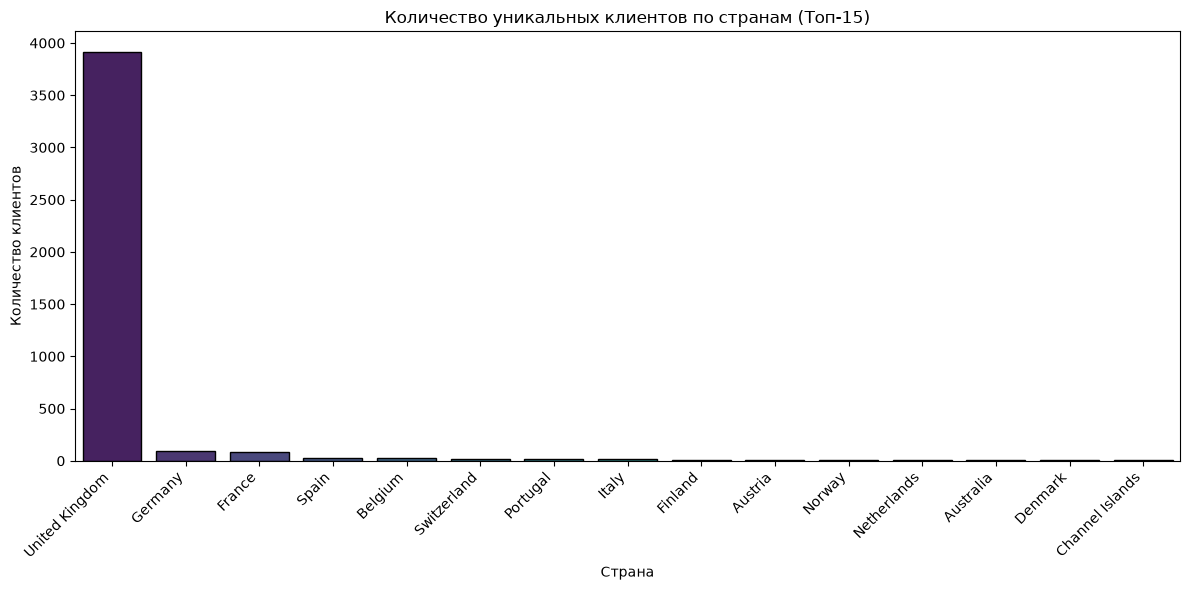

In [33]:
# 1. Считаем уникальных клиентов по странам
clients_per_country = data.groupby('Country')['CustomerID'].nunique().sort_values(ascending=False)

# 2. Выводим топ-5 стран для наглядности
print("Топ-5 стран по количеству уникальных клиентов:")
print(clients_per_country.head(5))

# 3. Строим график (возьмем топ-15 стран, чтобы график был читаемым)
plt.figure(figsize=(12, 6))
sns.barplot(x=clients_per_country.head(15).index, y=clients_per_country.head(15).values, palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Количество уникальных клиентов по странам (Топ-15)')
plt.xlabel('Страна')
plt.ylabel('Количество клиентов')
plt.tight_layout()
plt.show()

### Задание 4.2
Мы посмотрели на распределение клиентов в разрезе стран. А что насчёт заказов?

Постройте визуализацию и выделите топ-3 стран по количеству поступающих заказов.

* Великобритания (United Kingdom)
* Германия (Germany)
* Франция (France)
* Нидерланды (Netherlands)
* Ирландия (EIRE)
* Австралия (Australia)


### Задание 4.3
Давайте добавим в датасет общую цену заказа, назовём её TotalPrice.
Общая цена заказа рассчитывается как:
 
 **общая цена = цена за единицу товара * (количество товаров в заказе - количество возвращённых товаров).**

Чему равна средняя общая стоимость заказов? Ответ приведите в фунтах стерлингов и округлите до целого числа.



In [34]:
# 1. Создаем новый признак TotalPrice
data['TotalPrice'] = data['UnitPrice'] * (data['Quantity'] - data['QuantityCanceled'])

# 2. Считаем среднее значение и округляем до целого числа
average_total_price = round(data['TotalPrice'].mean())

print(f"Средняя общая стоимость заказов: {average_total_price} фунтов стерлингов")

Средняя общая стоимость заказов: 21 фунтов стерлингов


### Задание 4.4

Постройте визуализацию и выделите топ-3 стран, клиенты из которых приносят компании больше всего выручки:
* Великобритания (United Kingdom)
* Германия (Germany)
* Франция (France)
* Нидерланды (Netherlands)
* Ирландия (EIRE)
* Австралия (Australia)


Топ-3 стран по выручке:
Country
United Kingdom    6797691.44
Netherlands        283443.54
EIRE               247074.57
Name: TotalPrice, dtype: float64


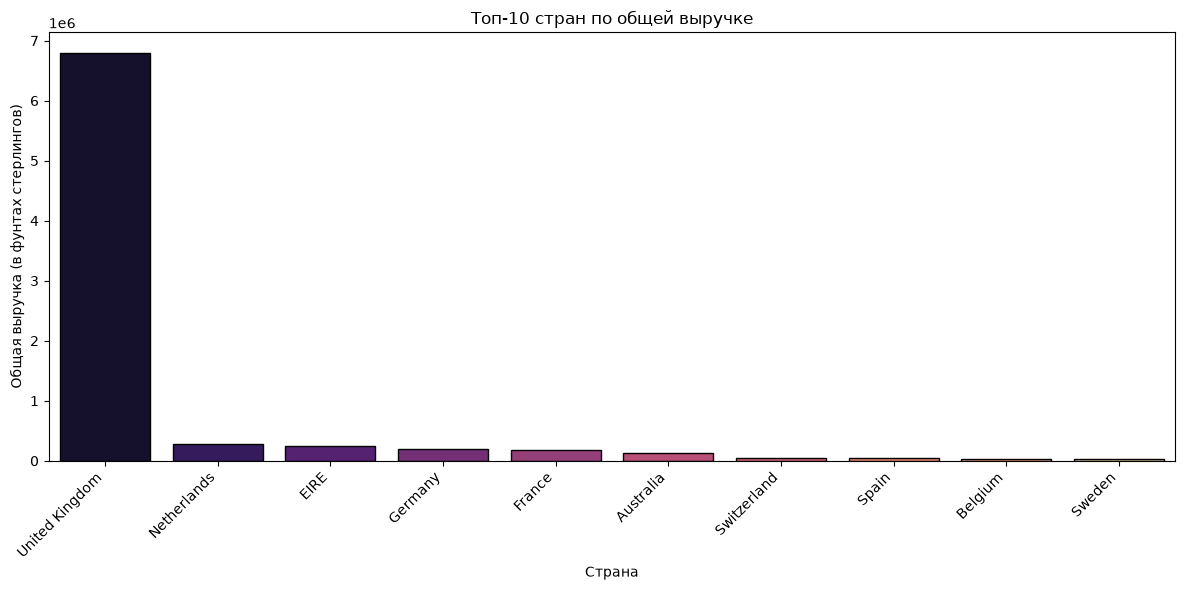

In [35]:
# 1. Считаем общую выручку по странам и сортируем по убыванию
revenue_per_country = data.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)

# 2. Выводим топ-3 стран
print("Топ-3 стран по выручке:")
print(revenue_per_country.head(3))

# 3. Строим график (возьмем топ-10 для наглядности)
plt.figure(figsize=(12, 6))
sns.barplot(x=revenue_per_country.head(10).index, y=revenue_per_country.head(10).values, palette='magma')
plt.xticks(rotation=45, ha='right')
plt.title('Топ-10 стран по общей выручке')
plt.xlabel('Страна')
plt.ylabel('Общая выручка (в фунтах стерлингов)')
plt.tight_layout()
plt.show()

Теперь займёмся временными характеристиками.


### Задание 4.5
Добавьте в таблицу с транзакциями признаки месяца, дня недели и часа совершения покупки.

Постройте визуализацию, отражающую распределение суммарной выручки от заказов по месяцам. Укажите номер самого прибыльного для компании месяца. Предположите, почему так происходит.

Суммарная выручка по месяцам:
Month
1      453560.68
2      436043.09
3      571941.01
4      447922.86
5      647403.81
6      601238.45
7      581019.35
8      614704.38
9      928554.44
10     967436.46
11    1119641.60
12     894126.86
Name: TotalPrice, dtype: float64


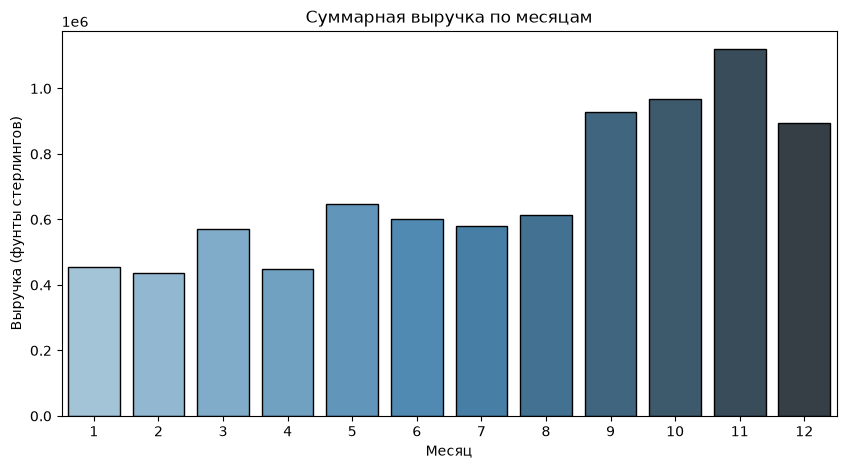


Самый прибыльный месяц: 11


In [36]:
# 1. Создаем новые признаки
data['Month'] = data['InvoiceDate'].dt.month
data['DayOfWeek'] = data['InvoiceDate'].dt.dayofweek
data['Hour'] = data['InvoiceDate'].dt.hour

# 2. Группируем выручку по месяцам
monthly_revenue = data.groupby('Month')['TotalPrice'].sum().sort_index()

# 3. Выводим данные
print("Суммарная выручка по месяцам:")
print(monthly_revenue)

# 4. Строим график
plt.figure(figsize=(10, 5))
sns.barplot(x=monthly_revenue.index, y=monthly_revenue.values, palette='Blues_d')
plt.title('Суммарная выручка по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Выручка (фунты стерлингов)')
plt.show()

# Находим самый прибыльный месяц
best_month = monthly_revenue.idxmax()
print(f"\nСамый прибыльный месяц: {best_month}")

### Задание 4.6
Постройте визуализацию количества заказов для каждого дня недели. Укажите день недели, в который, согласно данным, не совершено ни одного заказа:
* Понедельник
* Вторник
* Среда
* Четверг
* Пятница
* Суббота 
* Воскресенье


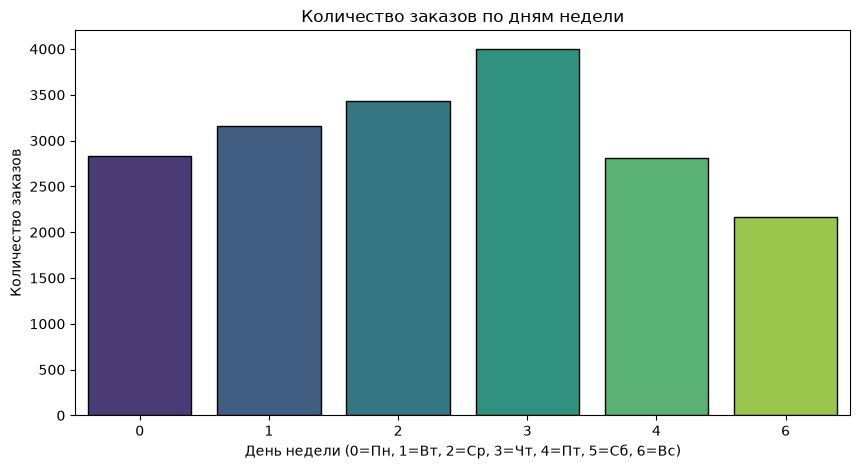

Количество заказов по дням (0=Пн, 6=Вс):
DayOfWeek
0    2830
1    3156
2    3436
3    4003
4    2809
6    2168
Name: InvoiceNo, dtype: int64


In [37]:
# 1. Считаем количество уникальных заказов для каждого дня недели
# Используем nunique() для InvoiceNo, чтобы посчитать именно заказы, а не строки
orders_by_day = data.groupby('DayOfWeek')['InvoiceNo'].nunique()

# 2. Строим график
plt.figure(figsize=(10, 5))
sns.barplot(x=orders_by_day.index, y=orders_by_day.values, palette='viridis')
plt.title('Количество заказов по дням недели')
plt.xlabel('День недели (0=Пн, 1=Вт, 2=Ср, 3=Чт, 4=Пт, 5=Сб, 6=Вс)')
plt.ylabel('Количество заказов')
plt.show()

# 3. Выводим результаты
print("Количество заказов по дням (0=Пн, 6=Вс):")
print(orders_by_day)

### Задание 4.7
Выделите дату из признака времени совершения транзакции.
Сгруппируйте данные по датам и часам совершения транзакции и найдите количество заказов на каждый день-час. Затем найдите среднее количество ежедневно поступающих заказов в каждый из часов.

Постройте визуализацию, отражающую распределение среднего количества ежедневно поступающих заказов по времени суток (часу совершения транзакции).

Выберите верные утверждения:
* Больше всего заказов совершается в дневное время в интервале от 18 до 20 часов
* Больше всего заказов совершается в вечернее время в интервале от 10 до 15 часов
* Начиная с 21 часа вечера и до 6 утра (не включительно) заказы не поступают 
* Заказы поступают во все периоды дня


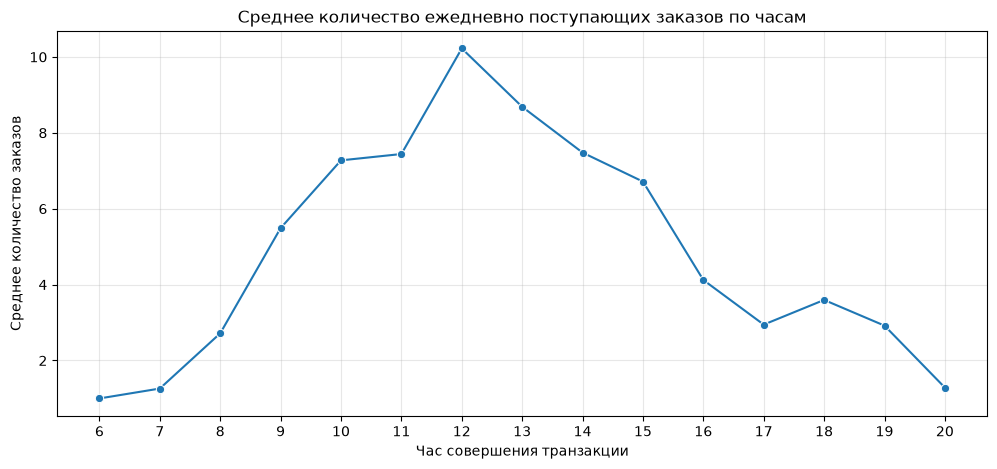

Hour
6      1.000000
7      1.260870
8      2.715686
9      5.488095
10     7.273927
11     7.440789
12    10.222951
13     8.685430
14     7.478405
15     6.714286
16     4.121212
17     2.945355
18     3.595745
19     2.918367
20     1.285714
Name: InvoiceNo, dtype: float64


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Выделяем дату (без времени)
data['Date'] = data['InvoiceDate'].dt.date

# 2. Считаем количество заказов на каждую пару "Дата + Час"
# Используем nunique(), чтобы посчитать именно уникальные заказы (счета)
orders_by_date_hour = data.groupby(['Date', 'Hour'])['InvoiceNo'].nunique().reset_index()

# 3. Находим среднее количество заказов для каждого часа
avg_orders_per_hour = orders_by_date_hour.groupby('Hour')['InvoiceNo'].mean()

# 4. Строим график
plt.figure(figsize=(12, 5))
sns.lineplot(x=avg_orders_per_hour.index, y=avg_orders_per_hour.values, marker='o')
plt.title('Среднее количество ежедневно поступающих заказов по часам')
plt.xlabel('Час совершения транзакции')
plt.ylabel('Среднее количество заказов')
plt.xticks(range(int(avg_orders_per_hour.index.min()), int(avg_orders_per_hour.index.max()) + 1))
plt.grid(True, alpha=0.3)
plt.show()

print(avg_orders_per_hour)

## 5. RFM-сегментация клиентов: часть 1

Мы добрались до самой интересной части нашей задачи. Нам предстоит сформировать признаки, на основе которых мы будем производить сегментацию клиентов.

Для этого давайте познакомимся с очень популярным методом для анализа потребительской ценности под названием RFM. 

<center> <img src=https://miro.medium.com/max/1400/1*uYQjy9SUjW7iWHc2gGanQQ.png align="right" width="400"/> </center>

Метод заключается в группировке клиентов на основе следующих параметров:
* Recency (Давность) — давность последней покупки клиента;
* Frequency (Частота) — общее количество покупок клиента;
* Monetary Value (Денежная ценность) — сколько денег потратил клиент.


Суть RFM-анализа состоит в том, что мы разделяем всех клиентов на группы в зависимости от того, как давно они сделали последнюю покупку, как часто покупали и насколько большой была сумма их заказов.

Например, вот так может выглядеть интерпретация кластеров для случая RF-сегментации (анализа на основе давности и частоты заказов клиента):

<img src=https://retailrocket.ru/wp-content/uploads/2017/06/rfm-1.png>

Задача маркетологов — вести клиента в зону лояльных.

Мы можем рассчитать RFM-характеристики для каждого из клиентов в нашем датасете и на их основе с помощью методов кластеризации построить подобные сегменты клиентов, привязанные к нашим данным.

### Задание 5.1

Итак, приступим к созданию нашей RFM-таблицы. 

Чтобы получить RFM-таблицу, нам необходимо сгруппировать данные по идентификаторам клиента и рассчитать следующие  агрегированные характеристики:

* Recency для i-го клиента рассчитывается как разница между датой и временем последнего заказа и точкой отсчёта, переведённая в дни:
    $$t_0-max(t_{i1}, t_{i2},..., t_{iM})$$

    где $t_{ij}$ — дата и время совершения i-ым клиентом своей j-ой покупки.

    В качестве точки отсчёта $t_0$ берём дату на один день «старше», чем все наши данные. Это будет 10 декабря 2011 года (в формате datetime — '2011-12-10 00:00:00').

* Frequency рассчитывается как общее количество уникальных заказов, которые совершил i-ый клиент.
* Monetary Value рассчитывается как общая сумма денег, которую i-ый клиент потратил на наши товары (с учетом возвратов).

Когда вы рассчитаете все характеристики, не забудьте дать столбцам результирующей таблицы соответствующие названия.

In [39]:
# 1. Задаем точку отсчета
reference_date = pd.to_datetime('2011-12-10 00:00:00')

# 2. Группируем данные по CustomerID и считаем агрегаты
rfm_table = data.groupby('CustomerID').agg({
    # Recency: разница между точкой отсчета и ПОСЛЕДНЕЙ датой покупки клиента (в днях)
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    
    # Frequency: количество уникальных заказов (счетов)
    'InvoiceNo': 'nunique',
    
    # Monetary: общая сумма покупок (TotalPrice мы уже создали ранее)
    'TotalPrice': 'sum'
})

# 3. Переименовываем столбцы для красоты
rfm_table.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'MonetaryValue'
}, inplace=True)

# 4. Смотрим, что получилось (выводим первые 5 строк, как на скриншоте)
display(rfm_table.head())

,Recency,Frequency,MonetaryValue
CustomerID,,,
12346,325,1,0.00
12347,2,7,4310.00
12348,75,4,1437.24
12349,18,1,1457.55
12350,310,1,294.40


1) Сколько клиентов совершили покупку более 200 дней назад?

2) Сколько заказов в среднем делает клиент (за представленный годовой период)? Ответ округлите до целого числа.

3) Чему равна общая сумма денег, которую потратил клиент с идентификатором 12360? Ответ приведите в фунтах стерлингов и округлите до целого числа.



In [40]:
# 1) Клиенты, совершившие покупку более 200 дней назад
# Считаем строки, где значение Recency > 200
customers_over_200 = rfm_table[rfm_table['Recency'] > 200].shape[0]
print(f"1) Клиентов, купивших более 200 дней назад: {customers_over_200}")

# 2) Среднее количество заказов на клиента
# Просто берем среднее значение столбца Frequency и округляем
avg_frequency = round(rfm_table['Frequency'].mean())
print(f"2) В среднем заказов на клиента: {avg_frequency}")

# 3) Общая сумма денег, потраченная клиентом 12360
# Обращаемся по индексу CustomerID
# Ищем ID как строку (в кавычках)
monetary_12360 = round(rfm_table.loc['12360', 'MonetaryValue'])
print(f"3) Сумма покупок клиента 12360: {monetary_12360} фунтов стерлингов")

1) Клиентов, купивших более 200 дней назад: 743
2) В среднем заказов на клиента: 4
3) Сумма покупок клиента 12360: 2302 фунтов стерлингов


Теперь давайте взглянем на коробчатые диаграммы для каждого из признаков:

In [41]:
boxes = [px.box(rfm_table, x=column) for column in rfm_table.columns]
fig = make_subplots(
    rows=1, cols=3, 
    subplot_titles=(
        "Recency","Frequency", "Monetary"
    )
)

for i, box in enumerate(boxes):
    fig.add_trace(boxes[i]['data'][0], row=1, col=i+1)

fig.update_layout(showlegend=True)
fig.show()

Что интересного здесь можно увидеть? Есть клиенты с аномально большим количеством сделанных заказов (более 100 штук), а также клиенты, общая стоимость заказов которых превышает 190 тысяч фунтов стерлингов.

Чем это плохо? Выбросы могут отрицательно сказаться на результатах работы методов кластеризации, неустойчивых к ним, например алгоритма KMeans, поэтому хотелось бы от них избавиться. Однако терять много ценных данных о клиентах тоже не хочется, поэтому ограничимся верхней границей соответствующей квантили уровня 0.95. Таким образом, мы удалим данные тех клиентов, для которых значение параметра Frequency или параметра Monetary выше, чем у 95 % клиентов.


### Задание 5.2
Удалите из RFM-таблицы записи о клиентах, для которых выполняется хотя бы одно из условий:

$frequency >frequency_{0.95}$

$monetary >monetary_{0.95}$ 

где $frequency_{0.95}$ и $monetary_{0.95}$ - квантили уровня 0.95 для соответствующих признаков. 

Данные о скольких клиентах у вас остались в RFM-таблице?


In [42]:
# 1. Находим квантили уровня 0.95 для Frequency и MonetaryValue
freq_95 = rfm_table['Frequency'].quantile(0.95)
mon_95 = rfm_table['MonetaryValue'].quantile(0.95)

print(f"Порог 95% для Frequency: {freq_95}")
print(f"Порог 95% для MonetaryValue: {mon_95}")

# 2. Фильтруем таблицу (оставляем только тех, кто НЕ превышает пороги)
rfm_table_clean = rfm_table[
    (rfm_table['Frequency'] <= freq_95) & 
    (rfm_table['MonetaryValue'] <= mon_95)
]

# 3. Считаем, сколько клиентов осталось
remaining_customers = rfm_table_clean.shape[0]

print(f"\nКоличество клиентов, оставшихся в RFM-таблице: {remaining_customers}")

Порог 95% для Frequency: 13.0
Порог 95% для MonetaryValue: 5659.851999999997

Количество клиентов, оставшихся в RFM-таблице: 4044


После удаления выбросов у вас должны получиться следующие коробчатые диаграммы:


In [43]:
boxes = [px.box(rfm_table_clean, x=column) for column in rfm_table_clean.columns]
fig = make_subplots(
    rows=1, cols=3, 
    subplot_titles=(
        "Recency", "Frequency", "Monetary"
    )
)

for i, box in enumerate(boxes):
    fig.add_trace(boxes[i]['data'][0], row=1, col=i+1)

fig.update_layout(showlegend=True)
fig.show()

Мы наконец добрались до этапа кластеризации. Для начала нам необходимо оценить, как распределены наблюдения в пространстве признаков. Благо, у нас всего три параметра, по которым мы хотим кластеризовать клиентов, поэтому данные можно визуализировать в виде трёхмерной диаграммы рассеяния. 

Построим визуализацию нашего трёхмерного пространства признаков:


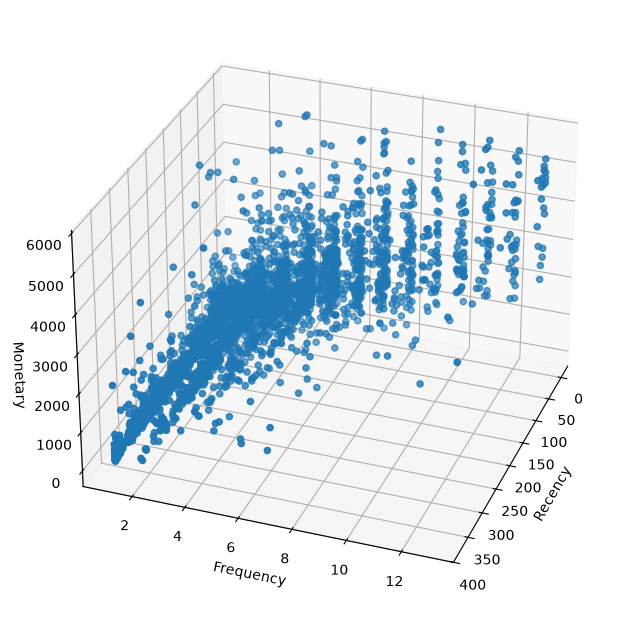

In [44]:
# создадим трёхмерный объект
fig = plt.figure(figsize=(6,6))
ax = Axes3D(fig)
# добавим дополнительную ось в объект картинки
fig.add_axes(ax)
ax.azim = 20
ax.elev = 30

# визуализируем данные, передав значения x, y, z, а также информацию о группировке данных по цветам
ax.scatter(
    rfm_table_clean['Recency'].to_list(), 
    rfm_table_clean['Frequency'].to_list(),
    rfm_table_clean['MonetaryValue'].to_list()
)
# добавим оси
ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary');


Что здесь можно увидеть? На самом деле, ничего конкретного. Да, видно, что есть клиенты с большими значениями параметров Monetary и Frequency — вероятно, это лучшие клиенты, которые покупают чаще всего и приносят больше всего денег. Однако по общей массе точек сложно сказать, сколько кластеров у нас есть — скорее даже кажется, что пространство не поддаётся кластеризации.

Давайте призовём на помощь методы снижения размерности.


### Задание 5.3
Начнём с метода главных компонент (PCA). Нам известно, что для его стабильной работы данные необходимо стандартизировать/нормализовать. 

Давайте для удобства обернём эти шаги по предобработке данных в pipeline.

Создайте pipeline, в котором будут следующие шаги:
* стандартизация с помощью StandardScaler с параметрами по умолчанию; 
* метод главных компонент с двумя компонентами.

Обучите ваш pipeline на RFM-таблице, очищенной от выбросов, и примените к ней трансформацию.

Какую долю дисперсии исходных данных объясняет первая главная компонента? Ответ округлите до двух знаков после точки-разделителя.



In [45]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Создаем pipeline из двух шагов: масштабирование и PCA
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
])

# 2. Обучаем pipeline и трансформируем очищенную RFM-таблицу
# (используем таблицу, из которой мы удалили выбросы в предыдущем задании)
rfm_pca = pipeline.fit_transform(rfm_table_clean)

# 3. Достаем долю объясненной дисперсии
# Обращаемся к шагу 'pca' нашего пайплайна
explained_variance = pipeline.named_steps['pca'].explained_variance_ratio_

print(f"Доля дисперсии 1-й компоненты: {round(explained_variance[0], 2)}")
print(f"Доля дисперсии 2-й компоненты: {round(explained_variance[1], 2)}")

Доля дисперсии 1-й компоненты: 0.68
Доля дисперсии 2-й компоненты: 0.24


Визуализировав пространство главных компонент после декомпозиции мы получим следующую картину:

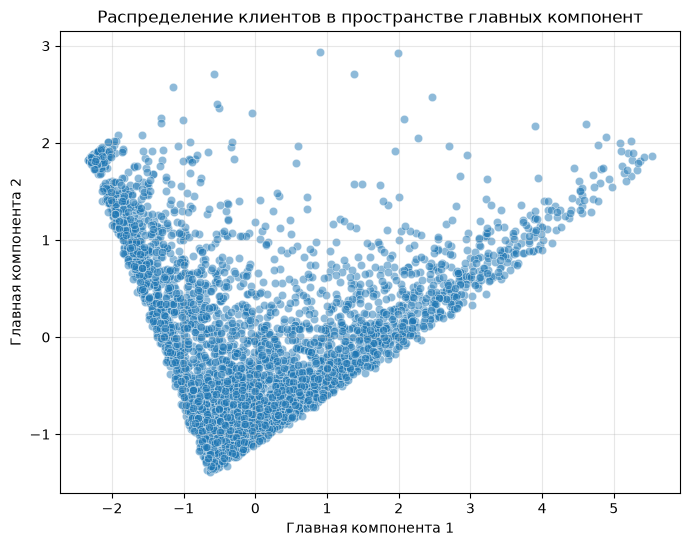

In [46]:
# 1. Создаем DataFrame из координат PCA (rfm_pca)
# Называем оси 'axis-1' и 'axis-2', как вы хотели в коде
rfm_pca_df = pd.DataFrame(rfm_pca, columns=['axis-1', 'axis-2'])

# 2. Строим график уже по правильному DataFrame
plt.figure(figsize=(8, 6))
sns.scatterplot(data=rfm_pca_df, x='axis-1', y='axis-2', alpha=0.5)
plt.title('Распределение клиентов в пространстве главных компонент')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.grid(True, alpha=0.3)
plt.show()

Попробуем разделить это пространство главных компонент на сегменты. 

### Задание 5.4
Попробуем воспользоваться методом k-means. 

Подберите оптимальное количество кластеров для метода k-means с помощью коэффициента силуэта, перебирая возможные значения от 2 до 10 включительно. 

В качестве значения параметра random_state возьмите число 42. Остальные параметры оставьте по умолчанию.

1) Судя по полученным результатам, какое количество кластеров лучше всего взять?

2) Чему равно максимальное значение коэффициента силуэта? Ответ округлите до двух знаков после точки-разделителя.


In [47]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Списки для хранения результатов
silhouette_scores = []
K_range = range(2, 11) # от 2 до 10 включительно

for k in K_range:
    # Обучаем модель
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(rfm_pca)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(rfm_pca, labels)
    silhouette_scores.append(score)
    print(f"k={k}, Silhouette Score: {score:.4f}")

# Находим оптимальное k (где скор максимальный)
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

print(f"\n1. Оптимальное количество кластеров: {best_k}")
print(f"2. Максимальное значение коэффициента силуэта: {round(best_score, 2)}")

k=2, Silhouette Score: 0.5002
k=3, Silhouette Score: 0.5242
k=4, Silhouette Score: 0.4976
k=5, Silhouette Score: 0.4547
k=6, Silhouette Score: 0.4480
k=7, Silhouette Score: 0.4196
k=8, Silhouette Score: 0.4294
k=9, Silhouette Score: 0.4072
k=10, Silhouette Score: 0.3975

1. Оптимальное количество кластеров: 3
2. Максимальное значение коэффициента силуэта: 0.52


### Задание 5.5
Теперь возьмём EM-алгоритм.

Подберите оптимальное количество кластеров для EM-алгоритма (GaussianMixture) с помощью коэффициента силуэта, перебирая возможные значения от 2 до 10 включительно.
В качестве значения параметра random_state возьмите число 42. Остальные параметры оставьте по умолчанию.


1) Судя по полученным результатам, какое количество кластеров лучше всего взять?

2) Чему равно максимальное значение коэффициента силуэта? Ответ округлите до двух знаков после точки-разделителя.


In [48]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# Списки для хранения результатов
silhouette_scores_gmm = []
K_range = range(2, 11) # от 2 до 10 включительно

for k in K_range:
    # Обучаем EM-алгоритм (GaussianMixture)
    gmm = GaussianMixture(n_components=k, random_state=42)
    
    # Получаем метки кластеров (predict возвращает номера кластеров)
    labels = gmm.fit_predict(rfm_pca)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(rfm_pca, labels)
    silhouette_scores_gmm.append(score)
    print(f"k={k}, Silhouette Score: {score:.4f}")

# Находим оптимальное k (где скор максимальный)
best_k_gmm = K_range[silhouette_scores_gmm.index(max(silhouette_scores_gmm))]
best_score_gmm = max(silhouette_scores_gmm)

print(f"\n1. Оптимальное количество кластеров (EM): {best_k_gmm}")
print(f"2. Максимальное значение коэффициента силуэта: {round(best_score_gmm, 2)}")

k=2, Silhouette Score: 0.3425
k=3, Silhouette Score: 0.4358
k=4, Silhouette Score: 0.3501
k=5, Silhouette Score: 0.2797
k=6, Silhouette Score: 0.2726
k=7, Silhouette Score: 0.2366
k=8, Silhouette Score: 0.1952
k=9, Silhouette Score: 0.1624
k=10, Silhouette Score: 0.1452

1. Оптимальное количество кластеров (EM): 3
2. Максимальное значение коэффициента силуэта: 0.44


### Задание 5.6
Давайте посмотрим на распределение кластеров.

1) Сначала нужно определить лучшую модель. Для какой модели с оптимальным количеством кластеров коэффициент силуэта наибольший?
* K-Means
* GaussianMixture


2) Обучите лучшую модель с подобранным ранее количеством кластеров на декомпозированных данных. 
Сколько клиентов попало в самый большой кластер?



In [49]:
from sklearn.cluster import KMeans

# 1. Обучаем K-means с оптимальным количеством кластеров 
best_k = 3

kmeans_best = KMeans(n_clusters=best_k, random_state=42, n_init=1)
labels_best = kmeans_best.fit_predict(rfm_pca)

# 2. Считаем количество клиентов в каждом кластере
cluster_counts = pd.Series(labels_best).value_counts()

print("Размеры кластеров:")
print(cluster_counts)

# 3. Находим самый большой кластер
max_cluster_size = cluster_counts.max()
print(f"\nКоличество клиентов в самом большом кластере: {max_cluster_size}")

Размеры кластеров:
2    2270
1    1001
0     773
Name: count, dtype: int64

Количество клиентов в самом большом кластере: 2270


Визуализируем результаты кластеризации:

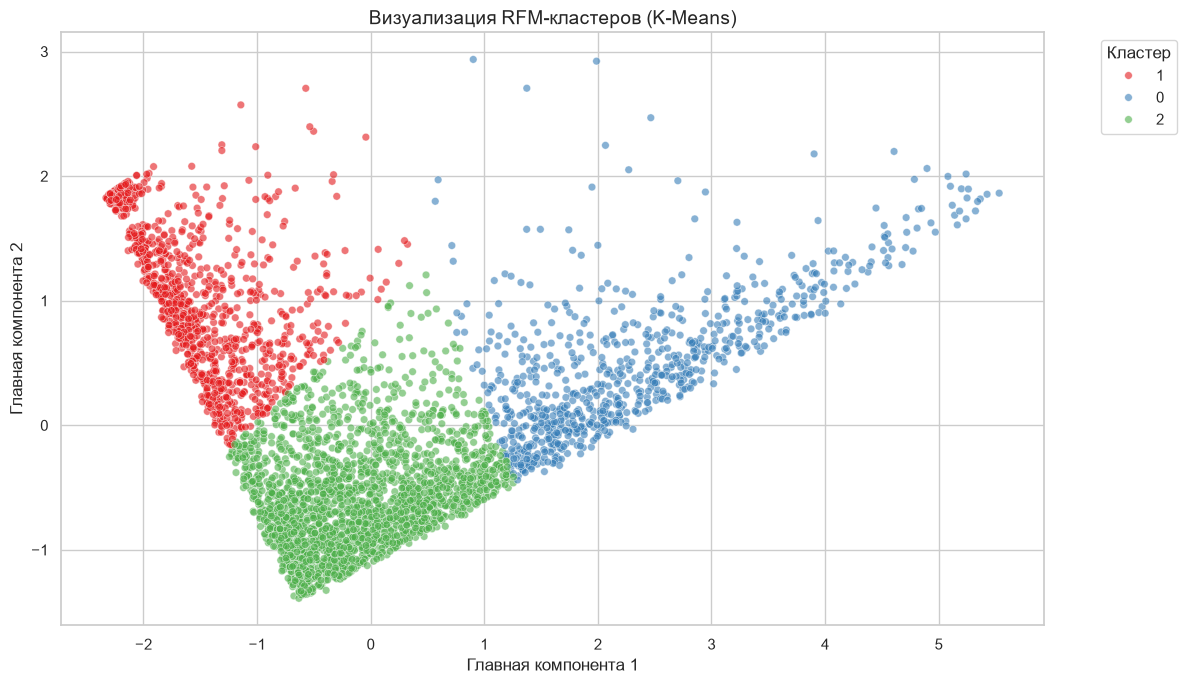

In [50]:
# 1. Создаем DataFrame для графика из координат PCA
plot_df = pd.DataFrame(rfm_pca, columns=['axis-1', 'axis-2'])

# 2. Добавляем метки кластеров (обязательно переводим в строку)
plot_df['Cluster'] = labels_best.astype(str)

# 3. Настраиваем стиль и размер графика
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# 4. Строим график рассеяния
sns.scatterplot(
    data=plot_df,
    x='axis-1',
    y='axis-2',
    hue='Cluster',
    palette='Set1',    # Используем контрастные цвета
    alpha=0.6,         # Делаем точки полупрозрачными, чтобы видеть плотность
    s=30               # Размер точек
)

# 5. Добавляем подписи и заголовок
plt.title('Визуализация RFM-кластеров (K-Means)', fontsize=14)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)

# 6. Выносим легенду за пределы графика, чтобы она не закрывала точки
plt.legend(title='Кластер', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Итак, у нас есть три сегмента клиентов. Давайте попробуем составить профиль для этих сегментов.

### Задание 5.7

Для составления профиля кластеров нам необходимо вернуться от декомпозированных данных к RFM-таблице, очищенной от выбросов.  Сгруппируйте RFM-таблицу по полученным кластерам и рассчитайте среднее по каждому из признаков.

Чему равно максимальное среднее значение признака Frequency в полученной таблице? Ответ округлите до целого числа.

In [51]:
# 1. Создаем копию очищенной таблицы
rfm_profiled = rfm_table_clean.copy()

# 2. Добавляем метки кластеров (используем labels_best из предыдущего шага)
rfm_profiled['Cluster'] = labels_best

# 3. Группируем по кластерам и считаем среднее
cluster_means = rfm_profiled.groupby('Cluster').mean()

# 4. Смотрим на получившуюся таблицу профилей
print("Средние значения признаков по кластерам:")
display(cluster_means)

# 5. Находим максимальное среднее значение для признака Frequency
max_freq_mean = cluster_means['Frequency'].max()

print(f"\nМаксимальное среднее значение Frequency: {round(max_freq_mean)}")

Средние значения признаков по кластерам:


,Recency,Frequency,MonetaryValue
Cluster,,,
0,32.010349,7.076326,2662.157012
1,253.283716,1.405594,386.598472
2,51.079295,2.332599,661.306912



Максимальное среднее значение Frequency: 7


### Полярная диаграмма
Сейчас мы познакомимся с одним из способов визуализации профиля кластеров — Radar Chart (полярная, или лепестковая, диаграмма). Это графическое представление значений нескольких эквивалентных категорий в форме «паутины».
Radar Chart очень часто используется в контексте определения профиля кластеров. На концах «паутины» откладываются оси, которые соответствуют признакам, описывающим объекты. На каждой из осей для каждого кластера откладываются средние значения соответствующих характеристик. Соединив точки по осям, мы получаем многоугольник. 
Пример полярной диаграммы для задачи кластеризации учеников по интересам:

<img src=https://www.datanovia.com/en/wp-content/uploads/2020/12/radar-chart-in-r-customized-fmstb-radar-chart-1.png width=500>

На данной диаграмме мы видим визуализацию признаков для одного из кластеров. Видно, что ученики, принадлежащие к данному кластеру, в большей степени увлекаются музыкой (Music), а в меньшей степени — программированием (Programm).

В модуле graph_objects библиотеки plotly есть встроенная функция Scatterpolar, которая позволяет построить полярную диаграмму. На основе этой функции мы реализовали собственную функцию plot_cluster_profile(), которая позволяет визуализировать профиль каждого из кластеров в виде полярной диаграммы. У этой функции два параметра: grouped_data — сгруппированные по кластерам характеристики объектов (клиентов), n_clusters — количество кластеров. 

Главное условие использования полярной диаграммы — все признаки должны быть приведены к единому масштабу с помощью нормализации, где 1 будет означать максимум, а 0 — минимум. Шаг с нормализацией мы также добавили в реализацию функции plot_cluster_profile().

In [52]:
def plot_cluster_profile(grouped_data, n_clusters):
    # Нормализуем сгруппированные данные, приводя их к масштабу 0-1.
    scaler = preprocessing.MinMaxScaler()
    grouped_data = pd.DataFrame(scaler.fit_transform(grouped_data), columns=grouped_data.columns)
    # Создаем список признаков
    features = grouped_data.columns
    # Создаем пустую фигуру
    fig = go.Figure()
    # В цикле визуализируем полярную диаграмму для каждого кластера
    for i in range(n_clusters):
        # Создаем полярную диаграмму и добавляем ее на общий график
        fig.add_trace(go.Scatterpolar(
            r=grouped_data.iloc[i].values, # радиусы
            theta=features, # название засечек
            fill='toself', # заливка многоугольника цветом
            name=f'Cluster {i}', # название - номер кластера
        ))
    # Обновляем параметры фигуры
    fig.update_layout(
        showlegend=True, # отображение легенды
        autosize=False, # устаналиваем свои размеры графика
        width=800, # ширина (в пикселях)
        height=800, # высота (в пикселях)
    )
    # Отображаем фигуру
    fig.show()
    

Теперь у нас есть удобный инструмент для анализа профиля кластеров. Давайте воспользуемся им.


### Задание 5.8

Визуализируйте профили кластеров в виде полярной диаграммы на основе средних RFM-характеристик, вычисленных для каждого кластера. 

Проанализируйте кластеры и на основе анализа сопоставьте номер кластера и его описание.

Описание кластера:
* Кластер соответствует «лояльным» клиентам, которые приносят наибольший доход, совершают покупки чаще всего, а давность их последней покупки наименьшая.
* Кластер соответствует «промежуточным» клиентам, которые являются активными, но покупают не так часто и много, как лояльные клиенты. В то же время эти клиенты не являются «потерянными».
* Кластер соответствует «потерянным» клиентам, которые купили меньше всего товара, и их последняя покупка была совершена очень давно.


In [53]:
plot_cluster_profile(cluster_means, n_clusters=3)

### 4. RFM-сегментация клиентов: часть 2

Итак, с помощью RFM-анализа нам удалось выделить три сегмента клиентов. Однако в маркетинге принято оперировать большим их количеством: обычно маркетологи стараются создать стратегию хотя бы для пяти-семи клиентских сегментов в градации от «лояльных» до «потерянных» с промежуточными категориями.

Поэтому, получив обратную связь от маркетологов, мы вновь принимаемся за работу, пытаясь модифицировать полученное решение.

Ранее мы производили кластеризацию в пространстве главных компонент. Вспомним, что PCA является линейным методом отображения исходного пространства признаков в его сжатую версию.

А что если использовать нелинейную трансформацию? Например, алгоритм снижения размерности t-SNE. Давайте попробуем и посмотрим, что получится.

### Задание 6.1
Воспользуемся алгоритмом t-SNE и трансформируем RFM-таблицу, очищенную от выбросов, в двухмерное представление. Также заранее позаботимся о масштабировании признаков.

Давайте для удобства обернём шаги по предобработке данных в pipeline.

Создайте pipeline, который будет содержать следующие шаги:
* стандартизация с помощью StandardScaler с параметрами по умолчанию; 
* алгоритм t-SNE с двумя компонентами, параметрами perplexity=50 и random_state=100.

Обучите ваш pipeline на RFM-таблице (очищенной от выбросов), полученной ранее, и примените к ней трансформацию.

Чему равно значение дивергенции Кульбака — Лейблера для обученного алгоритма t-SNE? Ответ округлите до двух знаков после точки-разделителя.

**Примечание:**
Напомним, что дивергенция Кульбака-Лейблера - это функция потерь, которая минимизируется при обучения алгоритма t-SNE. Она показывает меру расстояния между двумя распределениями. 

Оптимальное значение данной характеристики, найденное в процессе обучения алгоритма t-SNE, хранится в атрибуте kl_divergence_ объекта класса TSNE из библиотеки sklearn. Конечно же, предварительно модель необходимо обучить, чтобы получить это значение.



In [55]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
import pandas as pd

# 1. Готовим данные: берем ТОЛЬКО три признака, чтобы избежать утечки
rfm_for_tsne = rfm_table_clean[['Recency', 'Frequency', 'MonetaryValue']]

# 2. Создаем pipeline
tsne_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tsne', TSNE(n_components=2, perplexity=50, random_state=100, max_iter=1000))
])

# 3. Обучаем и трансформируем данные
rfm_tsne = tsne_pipeline.fit_transform(rfm_for_tsne)

# 4. Достаем значение дивергенции Кульбака-Лейблера (KL divergence)
# Обращаемся к шагу 'tsne' нашего пайплайна
kl_divergence = tsne_pipeline.named_steps['tsne'].kl_divergence_

print(f"Дивергенция Кульбака-Лейблера: {round(kl_divergence, 2)}")

Дивергенция Кульбака-Лейблера: 0.54


Визуализировав пространство после декомпозиции с помощью t-SNE, мы получим следующую картину:


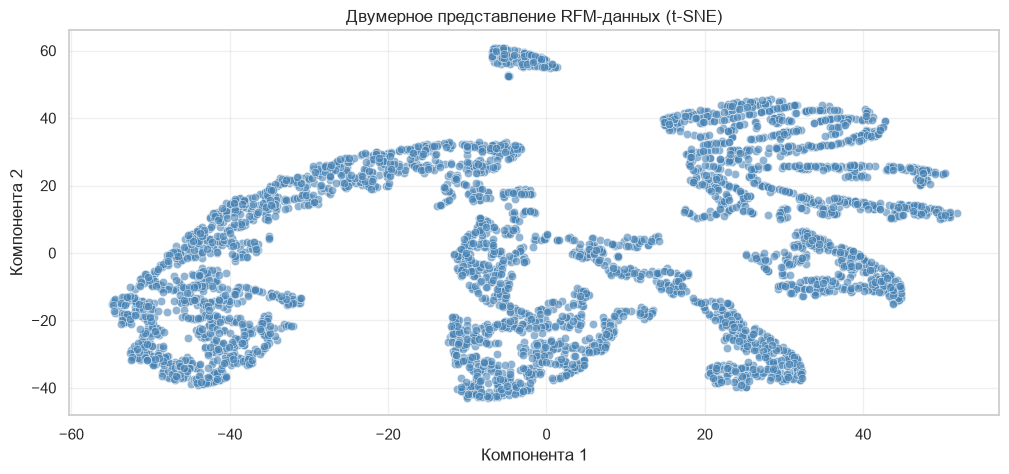

In [57]:
# 1. Создаем DataFrame из результатов t-SNE (массива rfm_tsne)
tsne_df = pd.DataFrame(rfm_tsne, columns=['axis-1', 'axis-2'])

# 2. Строим график
fig = plt.figure(figsize=(12, 5))
sns.scatterplot(data=tsne_df, x='axis-1', y='axis-2', alpha=0.6, color='steelblue')

plt.title('Двумерное представление RFM-данных (t-SNE)')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.grid(True, alpha=0.3)
plt.show()

Как и ожидалось от t-SNE, алгоритм сгруппировал наиболее похожие объекты в подобие кластеров, причём эти кластеры легко определить.

Теперь давайте воспользуемся алгоритмами кластеризации, чтобы сформировать новые сегменты клиентов.


### Задание 6.2
Попробуем воспользоваться методом k-means. 
Подберите оптимальное количество кластеров для метода k-means с помощью коэффициента силуэта, перебирая возможные значения от 3 до 8 включительно. 
В качестве значения параметра random_state возьмите число 42. Остальные параметры оставьте по умолчанию.

1) Судя по полученным результатам, какое количество кластеров лучше всего взять?

2) Чему равно максимальное значение коэффициента силуэта? Ответ округлите до двух знаков после точки-разделителя.



In [58]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Списки для хранения результатов
silhouette_scores = []
K_range = range(3, 9) # от 3 до 8 включительно

# Если данные после t-SNE в массиве rfm_tsne:
data_for_clustering = rfm_tsne 

for k in K_range:
    # Обучаем модель
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(data_for_clustering)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(data_for_clustering, labels)
    silhouette_scores.append(score)
    print(f"k={k}, Silhouette Score: {score:.4f}")

# Находим оптимальное k (где скор максимальный)
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

print(f"\n1. Оптимальное количество кластеров: {best_k}")
print(f"2. Максимальное значение коэффициента силуэта: {round(best_score, 2)}")

k=3, Silhouette Score: 0.4291
k=4, Silhouette Score: 0.4801
k=5, Silhouette Score: 0.4782
k=6, Silhouette Score: 0.4605
k=7, Silhouette Score: 0.4484
k=8, Silhouette Score: 0.4816

1. Оптимальное количество кластеров: 8
2. Максимальное значение коэффициента силуэта: 0.48


### Задание 6.3
Попробуем воспользоваться EM-алгоритом. 

Подберите оптимальное количество кластеров для EM-алгоритма (GaussianMixture)  с помощью коэффициента силуэта, перебирая возможные значения от 3 до 8 включительно. 

В качестве значения параметра random_state возьмите число 42. Остальные параметры оставьте по умолчанию.


1) Судя по полученным результатам, какое количество кластеров лучше всего взять?

2) Чему равно максимальное значение коэффициента силуэта? Ответ округлите до двух знаков после точки-разделителя.

In [59]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# Списки для хранения результатов
silhouette_scores_gmm = []
K_range = range(3, 9) # от 3 до 8 включительно

# Используем те же данные, что и для K-Means (например, rfm_tsne)
data_for_gmm = rfm_tsne 

for k in K_range:
    # Обучаем EM-алгоритм
    gmm = GaussianMixture(n_components=k, random_state=42)
    
    # Получаем метки кластеров
    labels = gmm.fit_predict(data_for_gmm)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(data_for_gmm, labels)
    silhouette_scores_gmm.append(score)
    print(f"k={k}, Silhouette Score: {score:.4f}")

# Находим оптимальное k (где скор максимальный)
best_k_gmm = K_range[silhouette_scores_gmm.index(max(silhouette_scores_gmm))]
best_score_gmm = max(silhouette_scores_gmm)

print(f"\n1. Оптимальное количество кластеров (EM): {best_k_gmm}")
print(f"2. Максимальное значение коэффициента силуэта: {round(best_score_gmm, 2)}")

k=3, Silhouette Score: 0.4270
k=4, Silhouette Score: 0.4652
k=5, Silhouette Score: 0.3889
k=6, Silhouette Score: 0.3841
k=7, Silhouette Score: 0.4472
k=8, Silhouette Score: 0.3854

1. Оптимальное количество кластеров (EM): 4
2. Максимальное значение коэффициента силуэта: 0.47


### Задание 6.4
Наконец, попробуем воспользоваться алгоритмом алгомеративной кластеризации (AgglomerativeClustering).

Подберите оптимальное количество кластеров для алгоритма агломеративной кластеризации с помощью коэффициента силуэта, перебирая возможные значения от 2 до 8 включительно. 

Все параметры, за исключением числа кластеров, оставьте по умолчанию.


1) Судя по полученным результатам, какое количество кластеров лучше всего взять?

2) Чему равно максимальное значение коэффициента силуэта? Ответ округлите до двух знаков после точки-разделителя.



In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Списки для хранения результатов
silhouette_scores_agg = []
K_range = range(2, 9) # от 2 до 8 включительно

# Используем те же данные
data_for_agg = rfm_tsne 

for k in K_range:
    # Обучаем модель
    agg = AgglomerativeClustering(n_clusters=k)
    labels = agg.fit_predict(data_for_agg)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(data_for_agg, labels)
    silhouette_scores_agg.append(score)
    print(f"k={k}, Silhouette Score: {score:.4f}")

# Находим оптимальное k (где скор максимальный)
best_k_agg = K_range[silhouette_scores_agg.index(max(silhouette_scores_agg))]
best_score_agg = max(silhouette_scores_agg)

print(f"\n1. Оптимальное количество кластеров: {best_k_agg}")
print(f"2. Максимальное значение коэффициента силуэта: {round(best_score_agg, 2)}")

k=2, Silhouette Score: 0.3752
k=3, Silhouette Score: 0.4027
k=4, Silhouette Score: 0.4672
k=5, Silhouette Score: 0.4343
k=6, Silhouette Score: 0.4292
k=7, Silhouette Score: 0.4114
k=8, Silhouette Score: 0.4380

1. Оптимальное количество кластеров: 4
2. Максимальное значение коэффициента силуэта: 0.47


### Задание 6.5
Давайте посмотрим на распределение кластеров.

1) Сначала нужно определить лучшую модель. Для какой модели с оптимальным количеством кластеров коэффициент силуэта наибольший?
* K-Means
* GaussianMixture
* AgglomerativeClustering


2) Обучите лучшую модель с подобранным ранее количеством кластеров на декомпозированных данных. 
Сколько клиентов попало в самый большой кластер?



In [64]:
# Обучаем K-means с 7 кластерами на t-SNE
kmeans_final = KMeans(n_clusters=7, random_state=42)
labels_final = kmeans_final.fit_predict(rfm_tsne)

# Считаем размеры кластеров
cluster_counts = pd.Series(labels_final).value_counts()

print(cluster_counts)
print(f"\nСамый большой кластер: {cluster_counts.max()}")

0    816
2    714
3    658
4    605
1    604
5    423
6    224
Name: count, dtype: int64

Самый большой кластер: 816


In [65]:
from sklearn.cluster import AgglomerativeClustering

# 1. Обучаем модель с 7 кластерами
agg_model_7 = AgglomerativeClustering(n_clusters=7)
labels_agg_7 = agg_model_7.fit_predict(rfm_tsne)

# 2. Считаем размеры кластеров
cluster_sizes = pd.Series(labels_agg_7).value_counts()

print("Размеры кластеров (Агломеративная кластеризация, 7 кластеров):")
print(cluster_sizes)

# 3. Максимальный кластер
print(f"\nСамый большой кластер: {cluster_sizes.max()}")

Размеры кластеров (Агломеративная кластеризация, 7 кластеров):
0    879
3    673
2    647
1    617
4    554
5    409
6    265
Name: count, dtype: int64

Самый большой кластер: 879


Визуализируем результаты кластеризации:

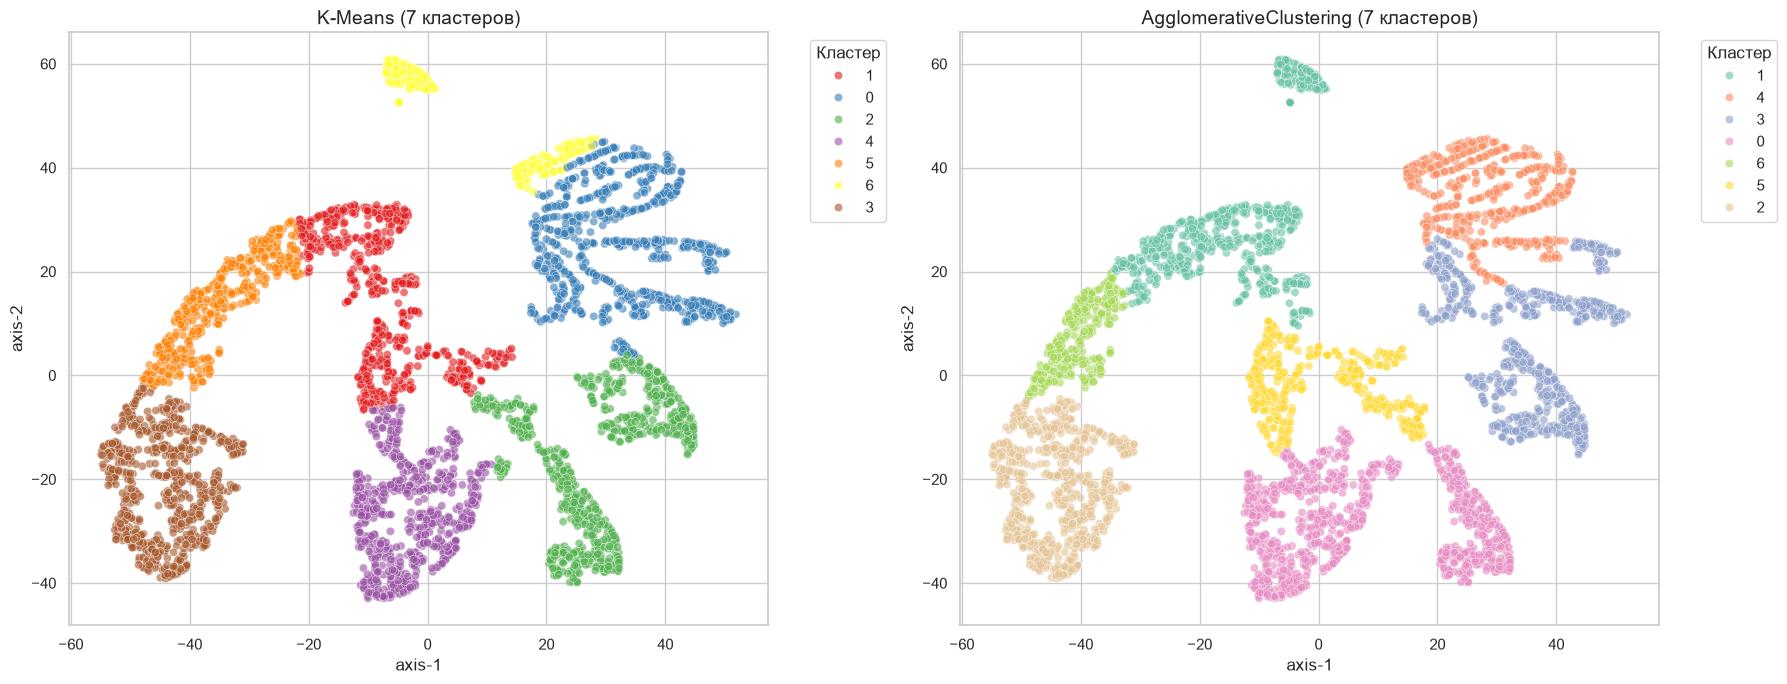

In [66]:
# --- 1. Обучаем модели на 7 кластеров (если вы еще не сделали этого) ---
kmeans_7 = KMeans(n_clusters=7, random_state=42)
labels_kmeans = kmeans_7.fit_predict(rfm_tsne)

agg_7 = AgglomerativeClustering(n_clusters=7)
labels_agg = agg_7.fit_predict(rfm_tsne)

# --- 2. Готовим DataFrame для графиков ---
plot_df = pd.DataFrame(rfm_tsne, columns=['axis-1', 'axis-2'])
plot_df['KMeans'] = labels_kmeans.astype(str) # Переводим в строку для категориальных цветов
plot_df['Agglomerative'] = labels_agg.astype(str)

# --- 3. Строим графики ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# График для K-Means
sns.scatterplot(
    data=plot_df, x='axis-1', y='axis-2', hue='KMeans', 
    palette='Set1', alpha=0.6, ax=axes[0]
)
axes[0].set_title('K-Means (7 кластеров)', fontsize=14)
axes[0].legend(title='Кластер', bbox_to_anchor=(1.05, 1), loc='upper left')

# График для Агломеративной кластеризации
sns.scatterplot(
    data=plot_df, x='axis-1', y='axis-2', hue='Agglomerative', 
    palette='Set2', alpha=0.6, ax=axes[1]
)
axes[1].set_title('AgglomerativeClustering (7 кластеров)', fontsize=14)
axes[1].legend(title='Кластер', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


Итак, у нас есть 7 сегментов клиентов. Давайте попробуем составить профиль для этих сегментов. 


### Задание 6.6

Для составления профиля кластеров нам необходимо вернуться от декомпозированных данных к RFM-таблице (очищенной от выбросов).

Сгруппируйте RFM-таблицу по полученным кластерам и рассчитайте среднее по каждому из признаков. Для наглядности округлите все значения в столбцах до целого числа.

Чему равно максимальное среднее значение признака Recency в полученной таблице? Ответ округлите до целого числа.

In [67]:
import pandas as pd

# 1. Создаем копию исходной очищенной RFM-таблицы
rfm_profile = rfm_table_clean.copy()

# 2. Добавляем метки кластеров 
# ВАЖНО: используйте те метки, которые относятся к вашей лучшей модели (например, labels_kmeans или labels_agg)
# Главное, чтобы их длина совпадала с длиной таблицы rfm_table_clean
rfm_profile['Cluster'] = labels_kmeans 

# 3. Группируем по кластерам и считаем средние значения
cluster_means = rfm_profile.groupby('Cluster').mean()

# 4. Округляем все значения в таблице до целых чисел для наглядности
cluster_means_rounded = cluster_means.round().astype(int)

# Выводим таблицу (названия столбцов должны совпадать: Recency, Frequency, MonetaryValue)
print("Профиль кластеров (средние значения):")
display(cluster_means_rounded)

# 5. Находим максимальное среднее значение для Recency
max_recency = cluster_means_rounded['Recency'].max()

print(f"\nМаксимальное среднее значение Recency: {max_recency}")

Профиль кластеров (средние значения):


,Recency,Frequency,MonetaryValue
Cluster,,,
0,34,6,2225
1,251,2,494
2,45,3,962
3,46,1,321
4,50,2,627
5,185,1,264
6,194,6,1976



Максимальное среднее значение Recency: 251


### Задание 6.7
Визуализируйте профили кластеров в виде полярной диаграммы на основе средних RFM-характеристик, вычисленных для каждого кластера.

Проанализируйте кластеры и на основе анализа сопоставьте номер кластера и его описание.

* Кластер соответствует «лояльным» клиентам, которые приносят наибольший доход, совершают покупки чаще всего, а давность их последней покупки наименьшая.
* Кластер соответствует «перспективным» клиентам, которые являются активными покупателями, но покупают не так часто и не так много, как лояльные клиенты.
* Кластер соответствует «подвисшим» клиентам, которые относительно недавно сделали несколько заказов на небольшие суммы. Потенциально эти клиенты могут быть переведены в кластер «перспективных».
* Кластер соответствует клиентам «в зоне риска», которые несколько раз покупали товары на небольшие суммы, однако их последняя покупка была совершена более пяти месяцев назад.
* Кластер соответствует клиентам-«новичкам», которые относительно недавно сделали один заказ на небольшую сумму. 
* Кластер соответствует «спящим» или «почти потерянным» клиентам, которые сделали один заказ на маленькую сумму более семи месяцев назад и больше не возвращались.
* Кластер соответствует «потерянным» клиентам, которые купили меньше всего товара, и их последняя покупка была совершена около года назад.



## 7. RFM-кластеризация клиентов: часть 3

Мы построили модель кластеризации для части клиентов.Но как сделать предсказание сегмента для клиентов, которые не попали в обучающую выборку?

Вы, вероятно, скажете: «Воспользоваться методом predict()!»

Верно, однако всё не так просто.

Вспомним, что мы обучали наши алгоритмы кластеризации на сжатом с помощью t-SNE пространстве признаков. То есть, чтобы сделать предсказание для новых объектов, не попавших в выборку, нам необходимо будет совершить трансформацию признаков этих объектов в новое сжатое пространство. 

Однако проблема t-SNE заключается в том, что алгоритм непараметрический. Это значит, что он, в отличие от таких алгоритмов, как PCA и SVD, не создаёт явной функции отображения. Проще говоря, алгоритм трансформирует пространство признаков для обучающей выборки, но не запоминает, каким образом это делает. Это значит, что, передав в алгоритм новые объекты для сжатия пространства, мы получим абсолютно новое представление пространства, не имеющее отношения к тому, что мы построили для обучающей выборки. То есть произойдёт искажение, что может привести к неверным результатам кластеризации.

Именно поэтому у класса TSNE из библиотеки sklearn нет такого метода, как transform(), у него есть только метод fit_transform() — заново обучить алгоритм t-SNE и произвести трансформацию.

Как же тогда производить кластеризацию для новых объектов, если мы не можем сжимать размерность для новых данных?

Давайте сведём задачу кластеризации к задаче классификации. Действительно, у нас теперь есть истинные метки кластеров, а есть клиенты, которые описываются RFM-характеристиками. Давайте обучим модель, которая на основе RFM-характеристик будет предсказывать клиентский сегмент. 

In [69]:
# Создаём матрицу наблюдений X и вектор правильных ответов y
X = rfm_table_clean #очищенная RFM-таблица
y = labels #метки кластеров, предсказанные ранее

### Задание 7.1

Разделите исходные данные на тренировочную и тестовую выборки в соотношении 80/20. В качестве параметра random_state возьмите число 42.

Сколько клиентов попали в тестовую выборку?

In [70]:
from sklearn.model_selection import train_test_split

# Разделяем данные (X - признаки, y - метки кластеров)
# test_size=0.2 означает 20% на тест и 80% на обучение
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

# Выводим количество клиентов (строк) в тестовой выборке
print(f"Количество клиентов в тестовой выборке: {X_test.shape[0]}")

Количество клиентов в тестовой выборке: 809


Дальше нам осталось только построить несколько моделей и выбрать из них лучшую. 
Мы знаем, что алгоритм t-SNE является нелинейным методом понижения размерности. Можно смело предположить, что линейные модели, такие как логистическая регрессия, в данной задаче нам мало чем помогут (можете убедиться в этом самостоятельно, обучив модель логистической регрессии на тренировочной выборке и оценив качество на тестовой).

Поэтому давайте сразу возьмём тяжелую артиллерию — ансамблевые алгоритмы. 


### Задание 7.2
Начнём со случайного леса. С помощью GridSearchCV организуйте перебор параметров случайного леса (RandomForestClassifier) на следующей сетке параметров:

```
param_grid = {
    'max_depth': range(5, 15),
    'criterion': ['gini', 'entropy'],
    'n_estimators': [100, 200, 500]
}
```
В качестве параметра random_state для модели случайного леса используйте число 42.
В качестве метрики используйте accuracy. Количество фолдов для кросс-валидации — 5.

1) Обучите GridSearchCV на тренировочной выборке. Чему равна оптимальная максимальная глубина деревьев в случайном лесу?

2) С помощью лучшей модели сделайте предсказание для тестовой выборки и рассчитайте метрику accuracy. Ответ округлите до трёх знаков после точки-разделителя.



In [71]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# 1. Задаем сетку параметров
param_grid = {
    'max_depth': range(5, 15),
    'criterion': ['gini', 'entropy'],
    'n_estimators': [100, 200, 500]
}

# 2. Инициализируем модель (random_state=42)
rf_model = RandomForestClassifier(random_state=42)

# 3. Настраиваем GridSearchCV (метрика accuracy, 5 фолдов)
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,      # Используем все ядра процессора для ускорения
    verbose=1       # Будем видеть прогресс
)

# 4. Обучаем на тренировочных данных
grid_search.fit(X_train, y_train)

# 5. Выводим оптимальную максимальную глубину
best_depth = grid_search.best_params_['max_depth']
print(f"1) Оптимальная максимальная глубина (max_depth): {best_depth}")

# 6. Делаем предсказание лучшей моделью на тесте и считаем accuracy
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"2) Accuracy на тестовой выборке: {round(test_accuracy, 3)}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits
1) Оптимальная максимальная глубина (max_depth): 14
2) Accuracy на тестовой выборке: 0.979


Итак, значение метрики accuracy очень высокое, но не идеальное. Давайте попробуем его улучшить, воспользовавшись бустингом.

### Задание 7.3
С помощью GridSearchCV организуйте перебор параметров градиентного бустинга (GradientBoostingClassifier) на следующей сетке параметров:
```
param_grid = {
    'max_depth': range(3, 7),
    'learning_rate': [0.001, 0.01, 0.1],
    'n_estimators': [100, 200, 500]
}
```

В качестве параметра random_state для модели градиентного бустинга используйте число 42.
В качестве метрики используйте accuracy. Количество фолдов для кросс-валидации — 5. 

1) Обучите GridSearchCV на тренировочной выборке. Чему равна оптимальная максимальная глубина деревьев в градиентном бустинге?
Ответ: 6
2) С помощью лучшей модели сделайте предсказание для тестовой выборки и рассчитайте метрику accuracy. Ответ округлите до трёх знаков после точки-разделителя.



In [72]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# 1. Задаем сетку параметров
param_grid_gb = {
    'max_depth': range(3, 7),
    'learning_rate': [0.001, 0.01, 0.1],
    'n_estimators': [100, 200, 500]
}

# 2. Инициализируем модель (random_state=42)
gb_model = GradientBoostingClassifier(random_state=42)

# 3. Настраиваем GridSearchCV
grid_search_gb = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid_gb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# 4. Обучаем
grid_search_gb.fit(X_train, y_train)

# 5. Проверяем глубину (для сверки)
print(f"Оптимальная глубина: {grid_search_gb.best_params_['max_depth']}")

# 6. Считаем accuracy на тесте
best_gb_model = grid_search_gb.best_estimator_
y_pred_gb = best_gb_model.predict(X_test)
test_accuracy_gb = accuracy_score(y_test, y_pred_gb)

print(f"Accuracy на тестовой выборке: {round(test_accuracy_gb, 3)}")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Оптимальная глубина: 5
Accuracy на тестовой выборке: 0.988


Отлично, мы справились с проблемой непараметричности t-SNE и смогли перейти от решения задачи кластеризации к задаче классификации. Теперь у нас есть модель, которая на основе RFM-характерик клиента автоматически определяет его сегмент.